# Estimación del resultado académico con Machine Learning clásico
**ACA 1 · Aprendizaje Automático · Especialización en Inteligencia Artificial · CUN**  
**Autor:** Wiliam Jhovany Sigindioy Miticanoy  
**Docente:** Dr. Hamilton Rivera Flor  
**Pilar:** Educación

## Objetivo general
Desarrollar un prototipo reproducible que prepare datos académicos, compare algoritmos clásicos de clasificación y despliegue el modelo seleccionado mediante una interfaz Streamlit para estimar el resultado académico registrado en el dataset.

## Situación problema y pregunta orientadora
Los registros académicos contienen información útil para analizar patrones de permanencia y abandono. ¿Cómo transformar la información disponible hasta el primer semestre en una estimación del resultado académico y presentarla mediante una interfaz interactiva comprensible?

El alcance es una clasificación de tres categorías: `Dropout` (abandono), `Enrolled` (matriculado) y `Graduate` (graduado). Estas etiquetas describen la situación registrada al término del periodo de observación del dataset; no representan una predicción de la duración exacta de los estudios.

## Resumen del proyecto
- Fuente: UCI Predict Students' Dropout and Academic Success, datos de educación superior de Portugal.
- Datos: 4.424 estudiantes, 36 variables explicativas y una columna objetivo.
- Modelo: ocho variables seleccionadas para simplificar el prototipo y su formulario.
- Evaluación: separación estratificada 80/20; validación cruzada de cinco particiones en entrenamiento; prueba final reservada.
- Despliegue: [aplicación Streamlit](https://aca1-ml-resultados-academicos-swrytvfe8v3bhdjmhmsine.streamlit.app/) y [repositorio](https://github.com/JhovanySigindioy/aca1-ml-resultados-academicos).

## Instrucciones de reproducción
Ejecutar en una sesión nueva de Google Colab, de arriba abajo. Instalar las dependencias iniciales y cargar únicamente `data.csv` cuando se solicite. Se mantienen las salidas originales del autor como evidencia; las celdas nuevas de preparación y empaquetado todavía no tienen salidas registradas.

Se fijan las versiones de scikit-learn, pandas y joblib observadas en el entrenamiento original. Si Colab indica que se debe reiniciar la sesión tras instalar, hacerlo antes de cargar el CSV y continuar desde la celda siguiente. El ZIP incluye un `requirements.txt` para ejecutar la app y un `requirements_entrenamiento.txt` para reproducir el análisis. La versión de Python utilizada en el nuevo entorno debe registrarse; para el despliegue se recomendó Python 3.11.

## 1. Preparar el entorno
Se instala scikit-learn 1.6.1 antes del entrenamiento. Entrenar con una versión y cambiarla después de serializar el modelo puede producir incompatibilidades al cargarlo.

In [ ]:
%pip -q install "scikit-learn==1.6.1" "pandas==2.2.3" "joblib==1.6.0" "matplotlib>=3.8,<4" "streamlit>=1.40,<2"

In [ ]:
import sys
import sklearn
import pandas as pd
import joblib
print("Python:", sys.version.split()[0])
print("scikit-learn:", sklearn.__version__)
print("pandas:", pd.__version__)
print("joblib:", joblib.__version__)
if sklearn.__version__ != "1.6.1":
    raise RuntimeError("Reinicia la sesión después de instalar y vuelve a ejecutar esta celda.")

## 2. Ingesta del dataset
El archivo original utiliza punto y coma como separador. Se eliminan espacios y tabulaciones de los nombres de columnas, incluida una tabulación en el encabezado de la jornada académica. Esta normalización no modifica los valores.

In [1]:
from google.colab import files
import pandas as pd
import io

archivos = files.upload()

df = pd.read_csv(
    io.BytesIO(archivos["data.csv"]),
    sep=";"
)

# Eliminar espacios y tabulaciones de los encabezados.
df.columns = df.columns.str.strip()

print("Filas y columnas:", df.shape)
display(df.head())
print("\nResultados académicos:")
display(df["Target"].value_counts())

Saving data.csv to data.csv
Filas y columnas: (4424, 37)


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate



Resultados académicos:


,count
Target,
Graduate,2209
Dropout,1421
Enrolled,794


## 3. Calidad de datos y caracterización inicial
Se revisan forma, faltantes, duplicados y distribución del objetivo. Las 4.424 filas no contienen faltantes ni duplicados completos, de modo que no se requiere imputar ni eliminar filas por esos motivos.

La clase Graduate representa 49,93 %, Dropout 32,12 % y Enrolled 17,95 %. Esta diferencia justifica usar F1 macro además de exactitud. No se interpretan los promedios de códigos nominales (por ejemplo Course o Nacionality) como magnitudes continuas; dichas variables no se utilizan en el modelo seleccionado.

No se eliminan observaciones por edad elevada ni por valores cero sin una justificación del diccionario de datos. Una calificación cero se conserva como valor registrado, no se reemplaza automáticamente por una calificación promedio.

In [2]:
print("Filas y columnas:", df.shape)
print("Total de valores faltantes:", df.isna().sum().sum())
print("Filas completamente duplicadas:", df.duplicated().sum())

print("\nDistribución del resultado académico:")
distribucion = df["Target"].value_counts().to_frame("estudiantes")
distribucion["porcentaje"] = (
    distribucion["estudiantes"] / len(df) * 100
).round(2)

display(distribucion)

print("\nResumen de las variables numéricas:")
display(df.describe().T)

Filas y columnas: (4424, 37)
Total de valores faltantes: 0
Filas completamente duplicadas: 0

Distribución del resultado académico:


,estudiantes,porcentaje
Target,,
Graduate,2209,49.93
Dropout,1421,32.12
Enrolled,794,17.95



Resumen de las variables numéricas:


,count,mean,std,min,25%,50%,75%,max
Marital status,4424.0,1.178571,0.605747,1.00,1.00,1.000000,1.000000,6.000000
Application mode,4424.0,18.669078,17.484682,1.00,1.00,17.000000,39.000000,57.000000
Application order,4424.0,1.727848,1.313793,0.00,1.00,1.000000,2.000000,9.000000
Course,4424.0,8856.642631,2063.566416,33.00,9085.00,9238.000000,9556.000000,9991.000000
Daytime/evening attendance,4424.0,0.890823,0.311897,0.00,1.00,1.000000,1.000000,1.000000
Previous qualification,4424.0,4.577758,10.216592,1.00,1.00,1.000000,1.000000,43.000000
Previous qualification (grade),4424.0,132.613314,13.188332,95.00,125.00,133.100000,140.000000,190.000000
Nacionality,4424.0,1.873192,6.914514,1.00,1.00,1.000000,1.000000,109.000000
Mother's qualification,4424.0,19.561935,15.603186,1.00,2.00,19.000000,37.000000,44.000000
Father's qualification,4424.0,22.275316,15.343108,1.00,3.00,19.000000,37.000000,44.000000


## 4. Variables seleccionadas y partición
Se seleccionan edad, calificación de admisión, calificación previa, beca y cuatro medidas del primer semestre: asignaturas inscritas, número de evaluaciones, asignaturas aprobadas y calificación. La selección busca un formulario manejable y variables académicas interpretables; no se realizó una búsqueda exhaustiva de las 36 variables.

Se excluyen expresamente los resultados del segundo semestre. El punto de uso planteado es disponer de información del primer semestre; no se presenta como predicción al momento de admisión.

Se reserva 20 % (885 filas) para la evaluación final. Las 3.539 filas de entrenamiento se utilizan para la exploración detallada, comparación y ajuste. La estratificación conserva aproximadamente las proporciones de clase. `random_state=42` fija la división aleatoria. La prueba final no participa en la elección de hiperparámetros.

In [3]:
from sklearn.model_selection import train_test_split

# Variables seleccionadas para el modelo y la futura aplicación.
variables = [
    "Age at enrollment",
    "Admission grade",
    "Previous qualification (grade)",
    "Scholarship holder",
    "Curricular units 1st sem (enrolled)",
    "Curricular units 1st sem (evaluations)",
    "Curricular units 1st sem (approved)",
    "Curricular units 1st sem (grade)"
]

X = df[variables].copy()
y = df["Target"].copy()

# Reservar el 20 % para la evaluación final.
# stratify conserva aproximadamente la proporción de cada clase.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Entrenamiento:", X_train.shape)
print("Prueba:", X_test.shape)

print("\nClases en entrenamiento:")
display(y_train.value_counts())

print("\nClases en prueba:")
display(y_test.value_counts())

Entrenamiento: (3539, 8)
Prueba: (885, 8)

Clases en entrenamiento:


,count
Target,
Graduate,1767
Dropout,1137
Enrolled,635



Clases en prueba:


,count
Target,
Graduate,442
Dropout,284
Enrolled,159


## 5. Análisis exploratorio del conjunto de entrenamiento
Los gráficos muestran la distribución del resultado y la relación descriptiva de aprobaciones y calificaciones con las etiquetas. Las diferencias no demuestran que una sola variable cause abandono o graduación.

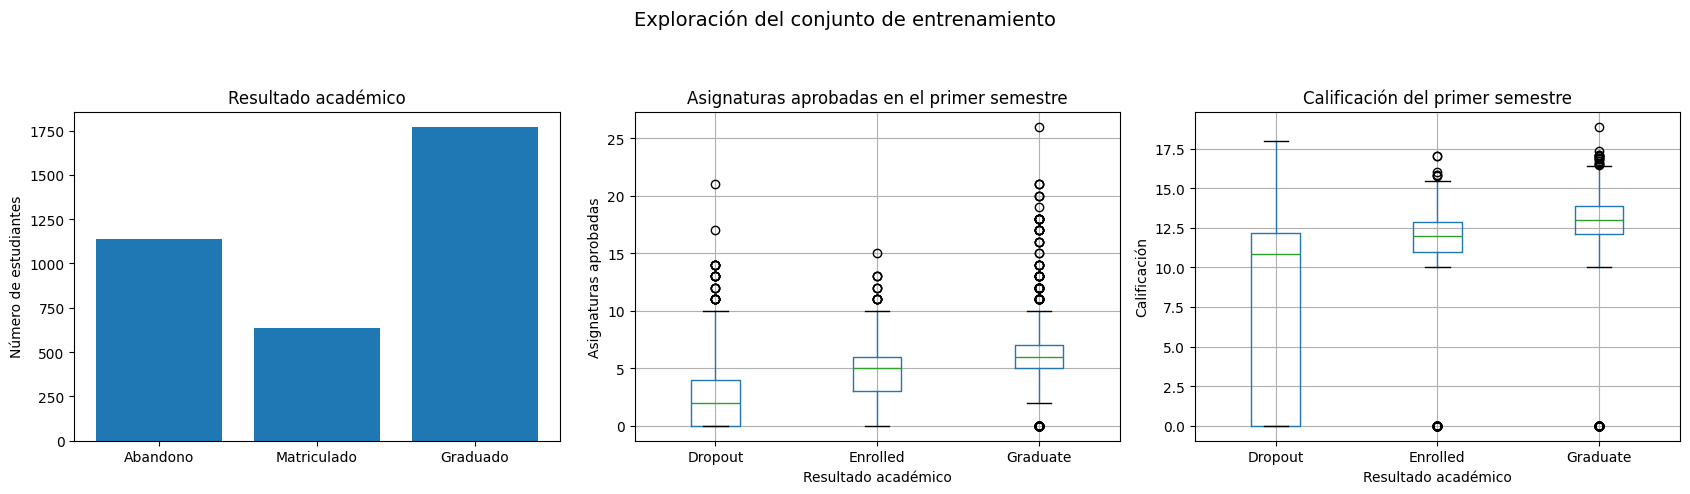

Promedios por resultado académico:


,Curricular units 1st sem (approved),Curricular units 1st sem (grade)
Resultado,,
Dropout,2.57,7.21
Enrolled,4.36,11.14
Graduate,6.20,12.63


In [4]:
import matplotlib.pyplot as plt

datos_train = X_train.copy()
datos_train["Resultado"] = y_train

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

orden = ["Dropout", "Enrolled", "Graduate"]
etiquetas = ["Abandono", "Matriculado", "Graduado"]

conteos = y_train.value_counts().reindex(orden)
axes[0].bar(etiquetas, conteos.values)
axes[0].set_title("Resultado académico")
axes[0].set_ylabel("Número de estudiantes")

datos_train.boxplot(
    column="Curricular units 1st sem (approved)",
    by="Resultado",
    ax=axes[1]
)
axes[1].set_title("Asignaturas aprobadas en el primer semestre")
axes[1].set_xlabel("Resultado académico")
axes[1].set_ylabel("Asignaturas aprobadas")

datos_train.boxplot(
    column="Curricular units 1st sem (grade)",
    by="Resultado",
    ax=axes[2]
)
axes[2].set_title("Calificación del primer semestre")
axes[2].set_xlabel("Resultado académico")
axes[2].set_ylabel("Calificación")

fig.suptitle("Exploración del conjunto de entrenamiento", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()

print("Promedios por resultado académico:")
display(
    datos_train.groupby("Resultado")[
        [
            "Curricular units 1st sem (approved)",
            "Curricular units 1st sem (grade)"
        ]
    ].mean().round(2)
)

### Interpretación de la exploración
En entrenamiento, el promedio de asignaturas aprobadas es 2,57 para Dropout, 4,36 para Enrolled y 6,20 para Graduate. Las calificaciones medias son 7,21, 11,14 y 12,63, respectivamente. Estas diferencias motivan probar las variables del primer semestre, aunque las distribuciones pueden solaparse y no permiten determinar con certeza la categoría individual.

## 6. Comparación de modelos clásicos
Se comparan cuatro alternativas usando las mismas cinco particiones estratificadas de entrenamiento:
- **DummyClassifier:** referencia mínima que predice siempre la clase mayoritaria.
- **Regresión logística:** referencia lineal; su StandardScaler se ajusta dentro de cada partición mediante Pipeline, evitando usar estadísticas de la partición de validación.
- **Árbol de decisión:** reglas no lineales con profundidad y tamaño mínimo de hoja limitados.
- **Bosque aleatorio:** conjunto de 200 árboles capaz de representar interacciones no lineales.

Los tres modelos predictivos usan `class_weight="balanced"` para ponderar las clases. No se altera el conjunto de prueba ni se aplica sobremuestreo. Los árboles no requieren escalado. F1 macro es el criterio principal y da el mismo peso a las tres clases; exactitud y desviación entre particiones se muestran como información complementaria.

In [5]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

modelos = {
    "Modelo básico": DummyClassifier(strategy="most_frequent"),

    "Regresión logística": Pipeline([
        ("escalado", StandardScaler()),
        ("modelo", LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=42
        ))
    ]),

    "Árbol de decisión": DecisionTreeClassifier(
        max_depth=5,
        min_samples_leaf=10,
        class_weight="balanced",
        random_state=42
    ),

    "Bosque aleatorio": RandomForestClassifier(
        n_estimators=200,
        max_depth=12,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=1
    )
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

resultados = []

for nombre, modelo in modelos.items():
    print("Evaluando:", nombre)

    scores = cross_validate(
        modelo,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "f1_macro": "f1_macro"
        },
        n_jobs=-1,
        error_score="raise"
    )

    resultados.append({
        "modelo": nombre,
        "accuracy_cv": scores["test_accuracy"].mean(),
        "f1_macro_cv": scores["test_f1_macro"].mean(),
        "desviacion_f1": scores["test_f1_macro"].std()
    })

comparacion = (
    pd.DataFrame(resultados)
    .sort_values("f1_macro_cv", ascending=False)
    .reset_index(drop=True)
)

display(comparacion.round(4))

Evaluando: Modelo básico
Evaluando: Regresión logística
Evaluando: Árbol de decisión
Evaluando: Bosque aleatorio


,modelo,accuracy_cv,f1_macro_cv,desviacion_f1
0,Bosque aleatorio,0.7013,0.6477,0.0090
1,Regresión logística,0.6841,0.6368,0.0091
2,Árbol de decisión,0.6431,0.6086,0.0118
3,Modelo básico,0.4993,0.2220,0.0002


### Comparación observada
| Modelo | Exactitud CV | F1 macro CV | Desviación F1 |
|---|---:|---:|---:|
| Bosque aleatorio | 0,7013 | 0,6477 | 0,0090 |
| Regresión logística | 0,6841 | 0,6368 | 0,0091 |
| Árbol de decisión | 0,6431 | 0,6086 | 0,0118 |
| Modelo básico | 0,4993 | 0,2220 | 0,0002 |

El bosque aleatorio logra la mayor media de F1 macro y se selecciona para el ajuste. La diferencia frente a la regresión logística no constituye por sí sola evidencia de superioridad estadística. La desviación entre particiones no es un intervalo de confianza.

## 7. Ajuste de hiperparámetros
GridSearchCV compara nueve combinaciones de profundidad máxima (8, 12 o sin límite) y mínimo de muestras por hoja (2, 5 o 10), usando F1 macro y cinco particiones. La mejor configuración es profundidad sin límite y mínimo de cinco muestras por hoja, con F1 macro CV 0,6489. La mejora sobre 0,6477 es pequeña.

`refit=True` vuelve a entrenar la configuración elegida con todo el conjunto de entrenamiento. La puntuación de la configuración ganadora se utilizó para seleccionar parámetros: no reemplaza una evaluación independiente. La misma partición de prueba permanece reservada.

In [7]:
from sklearn.model_selection import GridSearchCV

parametros = {
    "max_depth": [8, 12, None],
    "min_samples_leaf": [2, 5, 10]
}

busqueda = GridSearchCV(
    estimator=modelos["Bosque aleatorio"],
    param_grid=parametros,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    refit=True,
    error_score="raise"
)

busqueda.fit(X_train, y_train)

mejor_modelo = busqueda.best_estimator_

print("Mejores parámetros:", busqueda.best_params_)
print("Mejor F1 macro en validación:",
      round(busqueda.best_score_, 4))

tabla_ajuste = pd.DataFrame(busqueda.cv_results_)

display(
    tabla_ajuste[
        [
            "param_max_depth",
            "param_min_samples_leaf",
            "mean_test_score",
            "std_test_score",
            "rank_test_score"
        ]
    ]
    .sort_values("rank_test_score")
    .head(5)
)

Mejores parámetros: {'max_depth': None, 'min_samples_leaf': 5}
Mejor F1 macro en validación: 0.6489


,param_max_depth,param_min_samples_leaf,mean_test_score,std_test_score,rank_test_score
7,None,5,0.648894,0.009020,1
4,12,5,0.647665,0.009009,2
0,8,2,0.647295,0.007857,3
1,8,5,0.646691,0.010864,4
3,12,2,0.644614,0.007988,5


## 8. Evaluación final en prueba
Se aplica el modelo seleccionado a los 885 registros reservados. La matriz de confusión usa filas como clases reales y columnas como predicciones. Se presentan precisión, recall y F1 por clase, además de las métricas agregadas.

Métricas finales en el conjunto de prueba:


,modelo,accuracy,balanced_accuracy,f1_macro
0,Bosque aleatorio ajustado,0.678,0.6167,0.6166



Resultados por clase:
              precision    recall  f1-score   support

    Abandono     0.7166    0.6232    0.6667       284
 Matriculado     0.3436    0.4214    0.3785       159
    Graduado     0.8036    0.8054    0.8045       442

    accuracy                         0.6780       885
   macro avg     0.6213    0.6167    0.6166       885
weighted avg     0.6930    0.6780    0.6837       885



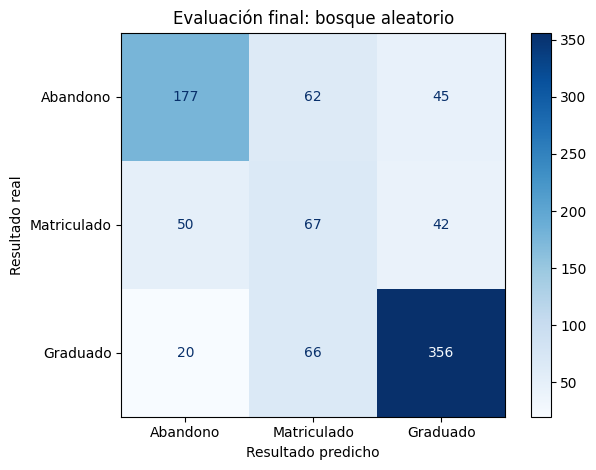

In [8]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# El mejor modelo ya quedó entrenado con X_train.
y_pred = mejor_modelo.predict(X_test)

metricas_prueba = pd.DataFrame([{
    "modelo": "Bosque aleatorio ajustado",
    "accuracy": accuracy_score(y_test, y_pred),
    "balanced_accuracy": balanced_accuracy_score(y_test, y_pred),
    "f1_macro": f1_score(y_test, y_pred, average="macro")
}])

print("Métricas finales en el conjunto de prueba:")
display(metricas_prueba.round(4))

orden_clases = ["Dropout", "Enrolled", "Graduate"]

print("\nResultados por clase:")
print(classification_report(
    y_test,
    y_pred,
    labels=orden_clases,
    target_names=["Abandono", "Matriculado", "Graduado"],
    digits=4,
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=orden_clases,
    display_labels=["Abandono", "Matriculado", "Graduado"],
    cmap="Blues",
    values_format="d"
)

plt.title("Evaluación final: bosque aleatorio")
plt.xlabel("Resultado predicho")
plt.ylabel("Resultado real")
plt.tight_layout()
plt.show()

### Interpretación de los resultados finales
| Métrica | Valor |
|---|---:|
| Exactitud | 0,6780 |
| Exactitud balanceada | 0,6167 |
| F1 macro | 0,6166 |

| Clase | Precisión | Recall | F1 | Casos reales |
|---|---:|---:|---:|---:|
| Abandono | 0,7166 | 0,6232 | 0,6667 | 284 |
| Matriculado | 0,3436 | 0,4214 | 0,3785 | 159 |
| Graduado | 0,8036 | 0,8054 | 0,8045 | 442 |

La exactitud indica que se clasificaron correctamente aproximadamente 67,8 % de los casos reservados. La exactitud balanceada es el promedio del recall por clase y reduce el predominio de la clase más frecuente en la interpretación.

Graduate es la clase con mayor F1. Enrolled es la más difícil: su precisión de 0,3436 implica que numerosas predicciones de matriculado corresponden a otras etiquetas; su recall de 0,4214 indica que se recupera menos de la mitad de los casos matriculados. Para Dropout, el recall 0,6232 implica que parte de los abandonos no es detectada.

El F1 macro final es inferior al de validación (0,6166 frente a 0,6489). Se informa esta diferencia sin reajustar el modelo a partir de la prueba. No se atribuyen causas a los errores ni se presentan las probabilidades del bosque como estimaciones calibradas.

## 9. Exportación del modelo y resultados
El archivo joblib contiene el clasificador, los nombres de variables en el orden esperado y las clases. Los metadatos JSON y las tablas CSV documentan la selección y evaluación. Se exporta el modelo ajustado solo con entrenamiento, que es el mismo que obtuvo las métricas finales; no se reentrena con las filas de prueba.

In [9]:
from pathlib import Path
import joblib
import json
import sklearn

carpeta = Path("proyecto_ml")
carpeta.mkdir(exist_ok=True)

# Guardar el modelo junto con el orden de sus variables.
paquete_modelo = {
    "modelo": mejor_modelo,
    "variables": variables,
    "clases": mejor_modelo.classes_.tolist()
}

joblib.dump(
    paquete_modelo,
    carpeta / "modelo_educacion.joblib"
)

# Guardar información para documentar y desplegar la aplicación.
metadatos = {
    "proyecto": "Predicción del resultado académico",
    "momento_prediccion": "Al finalizar el primer semestre",
    "variables": variables,
    "clases": mejor_modelo.classes_.tolist(),
    "parametros_ajustados": busqueda.best_params_,
    "f1_macro_validacion": float(busqueda.best_score_),
    "metricas_prueba": {
        "accuracy": float(metricas_prueba.iloc[0]["accuracy"]),
        "balanced_accuracy": float(
            metricas_prueba.iloc[0]["balanced_accuracy"]
        ),
        "f1_macro": float(metricas_prueba.iloc[0]["f1_macro"])
    },
    "version_scikit_learn": sklearn.__version__,
    "limitacion": (
        "Prototipo académico con menor desempeño en la clase "
        "Matriculado. No determina el futuro de un estudiante."
    )
}

with open(
    carpeta / "metadatos_modelo.json",
    "w",
    encoding="utf-8"
) as archivo:
    json.dump(metadatos, archivo, ensure_ascii=False, indent=2)

comparacion.to_csv(
    carpeta / "comparacion_modelos.csv",
    index=False
)

metricas_prueba.to_csv(
    carpeta / "metricas_prueba.csv",
    index=False
)

print("Archivos guardados:")
for archivo in sorted(carpeta.iterdir()):
    print("-", archivo.name)

print("\nVersión de scikit-learn:", sklearn.__version__)

Archivos guardados:
- comparacion_modelos.csv
- metadatos_modelo.json
- metricas_prueba.csv
- modelo_educacion.joblib

Versión de scikit-learn: 1.6.1


## 10. Interfaz Streamlit
La app carga los recursos desde su propia carpeta, solicita las ocho variables, conserva el orden de entrada y muestra la categoría y probabilidades estimadas. Valida que las aprobaciones no superen las asignaturas inscritas. Las escalas son las del dataset original: admisión y estudios previos hasta 200; primer semestre hasta 20. No se introducen directamente calificaciones colombianas de 0 a 5.

Los rangos de entrada corresponden a límites del prototipo, no a una validación de todos los casos educativos posibles. La app expone las métricas de prueba y aclara que el desempeño no está validado para CUN.

In [11]:
%%writefile proyecto_ml/app.py
from pathlib import Path
import json

import joblib
import pandas as pd
import streamlit as st

st.set_page_config(
    page_title="Resultado académico",
    page_icon="🎓",
    layout="wide"
)

BASE = Path(__file__).resolve().parent

@st.cache_resource
def cargar_recursos():
    paquete = joblib.load(BASE / "modelo_educacion.joblib")
    with open(
        BASE / "metadatos_modelo.json",
        encoding="utf-8"
    ) as archivo:
        metadatos = json.load(archivo)
    return paquete, metadatos

paquete, metadatos = cargar_recursos()
modelo = paquete["modelo"]
variables = paquete["variables"]

traducciones = {
    "Dropout": "Abandono",
    "Enrolled": "Matriculado",
    "Graduate": "Graduado"
}

st.title("🎓 Estimación del resultado académico")
st.caption(
    "ACA 1 · Aprendizaje Automático · CUN · "
    "Wiliam Jhovany Sigindioy Miticanoy"
)

st.write(
    "Prototipo académico que utiliza información del primer semestre "
    "para estimar una de las tres categorías del dataset: "
    "abandono, matriculado o graduado."
)

st.info(
    "El modelo se entrenó con datos de una institución de educación "
    "superior de Portugal. Su desempeño no está validado para la CUN. "
    "La predicción no determina el futuro de un estudiante."
)

with st.form("formulario_academico"):
    st.subheader("Información del estudiante")
    izquierda, derecha = st.columns(2)

    with izquierda:
        edad = st.number_input(
            "Edad al ingresar",
            min_value=17, max_value=70, value=20
        )
        admision = st.number_input(
            "Calificación de admisión · escala 0–200",
            min_value=95.0, max_value=200.0,
            value=127.0, step=0.1
        )
        previa = st.number_input(
            "Calificación de estudios previos · escala 0–200",
            min_value=95.0, max_value=200.0,
            value=133.0, step=0.1
        )
        beca = st.selectbox(
            "¿Tiene beca?",
            options=["No", "Sí"]
        )

    with derecha:
        inscritas = st.number_input(
            "Asignaturas inscritas en el primer semestre",
            min_value=0, max_value=26, value=6
        )
        evaluaciones = st.number_input(
            "Número de evaluaciones en el primer semestre",
            min_value=0, max_value=45, value=8
        )
        aprobadas = st.number_input(
            "Asignaturas aprobadas en el primer semestre",
            min_value=0, max_value=26, value=5
        )
        nota = st.number_input(
            "Calificación del primer semestre · escala 0–20",
            min_value=0.0, max_value=20.0,
            value=12.0, step=0.1
        )

    st.caption(
        "Introduce las calificaciones en las escalas originales "
        "del dataset; no uses directamente notas colombianas de 0 a 5."
    )

    enviado = st.form_submit_button("Estimar resultado")

if enviado:
    if aprobadas > inscritas:
        st.error(
            "Las asignaturas aprobadas no pueden superar "
            "las asignaturas inscritas."
        )
    else:
        datos = {
            "Age at enrollment": edad,
            "Admission grade": admision,
            "Previous qualification (grade)": previa,
            "Scholarship holder": int(beca == "Sí"),
            "Curricular units 1st sem (enrolled)": inscritas,
            "Curricular units 1st sem (evaluations)": evaluaciones,
            "Curricular units 1st sem (approved)": aprobadas,
            "Curricular units 1st sem (grade)": nota
        }

        entrada = pd.DataFrame([datos])[variables]
        prediccion = modelo.predict(entrada)[0]
        probabilidades = modelo.predict_proba(entrada)[0]

        st.subheader(
            f"Resultado estimado: {traducciones[prediccion]}"
        )

        tabla = pd.DataFrame({
            "Categoría": [
                traducciones[clase] for clase in modelo.classes_
            ],
            "Probabilidad estimada": probabilidades
        }).set_index("Categoría")

        st.bar_chart(tabla)
        st.caption(
            "Las probabilidades del modelo no fueron calibradas. "
            "No representan certezas sobre un caso individual."
        )

        with st.expander("Ver valores utilizados"):
            st.dataframe(entrada)

st.divider()
st.subheader("Evaluación del modelo")

metricas = metadatos["metricas_prueba"]
col1, col2, col3 = st.columns(3)

col1.metric("Exactitud en prueba", f"{metricas['accuracy']:.1%}")
col2.metric("F1 macro en prueba", f"{metricas['f1_macro']:.4f}")
col3.metric(
    "Exactitud balanceada",
    f"{metricas['balanced_accuracy']:.4f}"
)

st.caption(
    "Evaluación sobre 885 registros reservados. "
    "La clase Matriculado obtuvo el menor F1: 0,3785."
)

with st.expander("Metodología y fuente"):
    st.write(
        "Se compararon un modelo básico, regresión logística, "
        "árbol de decisión y bosque aleatorio mediante validación "
        "cruzada estratificada de cinco particiones. "
        "El bosque aleatorio se ajustó usando F1 macro."
    )
    st.write(
        "El conjunto de prueba no se utilizó para seleccionar "
        "los parámetros. Se emplearon ocho variables disponibles "
        "al finalizar el primer semestre."
    )
    st.markdown(
        "[Dataset original en UCI]"
        "(https://archive.ics.uci.edu/dataset/697/"
        "predict+students+dropout+and+academic+success)"
    )

Overwriting proyecto_ml/app.py


In [12]:
import pandas as pd
import joblib
from pathlib import Path

requisitos = [
    "streamlit>=1.40,<2",
    "scikit-learn==1.6.1",
    f"pandas=={pd.__version__}",
    f"joblib=={joblib.__version__}"
]

ruta = Path("proyecto_ml/requirements.txt")
ruta.write_text("\n".join(requisitos) + "\n", encoding="utf-8")

print("requirements.txt creado:")
print(ruta.read_text())

requirements.txt creado:
streamlit>=1.40,<2
scikit-learn==1.6.1
pandas==2.2.3
joblib==1.6.0



### Comprobación de dependencias
La instalación se realiza al inicio para que las versiones de entrenamiento y carga del modelo sean coherentes. El archivo requirements.txt generado se entrega junto con app.py.

In [ ]:
from pathlib import Path
print(Path("proyecto_ml/requirements.txt").read_text())

## 11. Prueba funcional de la interfaz
AppTest carga la aplicación y simula el envío del formulario con los valores iniciales. La ejecución original cargó los recursos sin excepciones y devolvió Matriculado. Esta comprobación es funcional y no mide precisión adicional ni sustituye la inspección visual en el navegador. El autor también comprobó el acceso público en una ventana de incógnito.

In [14]:
from pathlib import Path
from streamlit.testing.v1 import AppTest

ruta_app = Path("proyecto_ml/app.py").resolve()

prueba = AppTest.from_file(
    str(ruta_app),
    default_timeout=60
).run()

assert not prueba.exception, "La aplicación produjo un error al iniciar."
print("✓ Aplicación y modelo cargados correctamente.")

# Simular el botón usando los valores iniciales del formulario.
prueba.button[0].click().run()

assert not prueba.exception, "Ocurrió un error al calcular la predicción."

resultados = [
    elemento.value
    for elemento in prueba.subheader
    if elemento.value.startswith("Resultado estimado:")
]

assert resultados, "No se mostró el resultado de la predicción."

print("✓ Botón de predicción funcionando.")
print(resultados[0])

2026-11-02 02:28:27.040 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


✓ Aplicación y modelo cargados correctamente.
✓ Botón de predicción funcionando.
Resultado estimado: Matriculado


## 12. Preparación del paquete reproducible
Además de la app y los resultados, el paquete incluye el CSV original con su referencia, instrucciones y dependencias para entrenamiento. El notebook ejecutado se descarga por separado desde Archivo → Descargar → .ipynb y debe añadirse al ZIP de entrega. No se genera un notebook vacío para sustituir las salidas originales.

In [ ]:
from pathlib import Path

carpeta = Path("proyecto_ml")
carpeta.mkdir(exist_ok=True)
(carpeta / "data.csv").write_bytes(archivos["data.csv"])

requisitos_entrenamiento = (carpeta / "requirements.txt").read_text()
requisitos_entrenamiento += "matplotlib>=3.8,<4\n"
(carpeta / "requirements_entrenamiento.txt").write_text(
    requisitos_entrenamiento, encoding="utf-8"
)

readme = """# ACA 1 - Estimación del resultado académico
Autor: Wiliam Jhovany Sigindioy Miticanoy. CUN, Aprendizaje Automático.

## Ejecutar la app
Con Python 3.11 y un entorno virtual:
pip install -r requirements.txt
streamlit run app.py

El modelo requiere scikit-learn 1.6.1. Mantener app.py,
modelo_educacion.joblib y metadatos_modelo.json en la misma carpeta.

## Reproducir entrenamiento
Abrir el notebook de entrega en Google Colab. Ejecutar sus celdas en orden
y cargar data.csv cuando lo solicite. No necesita GPU ni API keys.
Para Jupyter local, instalar requirements_entrenamiento.txt y adaptar
la celda de subida de Colab a pd.read_csv('data.csv', sep=';').
Añadir el notebook ejecutado descargado de Colab al ZIP de entrega.

## Datos y alcance
4.424 filas; ocho variables predictoras hasta el primer semestre;
clasificación Dropout, Enrolled y Graduate. Datos de Portugal;
prototipo sin validación para Colombia o CUN.
Fuente: Realinho, V., Vieira Martins, M., Machado, J., & Baptista, L. (2021).
Predict Students' Dropout and Academic Success [Dataset]. UCI.
https://doi.org/10.24432/C5MC89
Licencia del dataset: Creative Commons Attribution 4.0 International.

## Resultados observados
Prueba: exactitud 0.6780, exactitud balanceada 0.6167, F1 macro 0.6166.
La clase Enrolled obtuvo F1 0.3785. Probabilidades no calibradas.

## Enlaces
App: https://aca1-ml-resultados-academicos-swrytvfe8v3bhdjmhmsine.streamlit.app/
Repositorio: https://github.com/JhovanySigindioy/aca1-ml-resultados-academicos
"""
(carpeta / "README.md").write_text(readme, encoding="utf-8")
print("Dataset, instrucciones y requisitos de entrenamiento preparados.")

In [15]:
import shutil
from google.colab import files

ruta_zip = shutil.make_archive(
    "ACA1_ML_Streamlit",
    "zip",
    root_dir="proyecto_ml"
)

files.download(ruta_zip)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 13. Conclusiones y limitaciones
Se desarrolló un flujo que comprende lectura y revisión de calidad de datos, selección justificada de variables, exploración, comparación de modelos, ajuste, evaluación independiente y despliegue interactivo.

El bosque aleatorio obtuvo el mejor F1 macro medio entre las alternativas comparadas y se desplegó con ocho entradas. Su exactitud en prueba fue 67,8 %; el desempeño inferior para Enrolled limita su utilidad como herramienta de apoyo individual.

La selección de ocho variables facilita la interfaz, pero excluye información que podría aportar capacidad predictiva. Los promedios exploratorios y las predicciones no demuestran causalidad. Los datos proceden de una institución portuguesa, por lo que no se afirma generalización a CUN ni a estudiantes colombianos.

Este diseño aleatorio no constituye una validación temporal o externa. La información del primer semestre puede reflejar situaciones ya ocurridas durante ese semestre; el experimento no prueba una alerta prospectiva antes de que suceda el abandono. Las clases se interpretan según el periodo de observación de la fuente.

Como trabajo futuro se propone evaluar en cohortes temporales o instituciones externas, revisar errores por subgrupo, calibrar probabilidades y comparar conjuntos de variables definidos antes de evaluar. Una nueva fase de desarrollo requeriría una nueva evaluación independiente, sin utilizar repetidamente este conjunto de prueba para seleccionar mejoras.

## 14. Referencias
- Realinho, V., Vieira Martins, M., Machado, J., & Baptista, L. (2021). *Predict Students' Dropout and Academic Success* [Conjunto de datos]. UCI Machine Learning Repository. https://doi.org/10.24432/C5MC89
- Scikit-learn developers. (s. f.). *Scikit-learn 1.6 documentation*. https://scikit-learn.org/1.6/
- Streamlit. (s. f.). *Streamlit documentation*. https://docs.streamlit.io/
- Joblib developers. (s. f.). *Joblib documentation*. https://joblib.readthedocs.io/

## 15. Enlaces del proyecto
- [Repositorio GitHub](https://github.com/JhovanySigindioy/aca1-ml-resultados-academicos)
- [Aplicación Streamlit](https://aca1-ml-resultados-academicos-swrytvfe8v3bhdjmhmsine.streamlit.app/)

El póster y el video de sustentación se preparan después de cerrar este notebook. Sus enlaces se incorporarán cuando estén disponibles.